# Captcha Text Recognition using Custom CNN-RNN Models

## Imports

In [ ]:
import os
from pathlib import Path
from PIL import Image

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset,DataLoader
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## Data Loading and Setup

In [ ]:
!unzip -oq cig_ps.zip

data_dir = Path("/content/cig_ps")
train_dir = data_dir / "train_images"
test_dir = data_dir / "test_images"
labels_file = data_dir / "train-labels.csv"

print("Train folder:", train_dir.exists())
print("Test folder:", test_dir.exists())
print("Labels file:", labels_file.exists())

Train folder: True
Test folder: True
Labels file: True


## Dataset Overview

In [ ]:
labels = pd.read_csv(labels_file,dtype={"text": str})
print("Shape:",labels.shape)
print("Columns:",labels.columns.tolist())
labels.head()

Shape: (20000, 3)
Columns: ['Unnamed: 0', 'image', 'text']


,Unnamed: 0,image,text
0,0,train-0.png,BU522X
1,1,train-1.png,XQ8NE2
2,2,train-2.png,DTZD3E
3,3,train-3.png,SM424H
4,4,train-4.png,6YVTQR


In [ ]:
labels = labels[["image", "text"]].copy()

print("Minimum label length:", labels["text"].str.len().min())
print("Maximum label length:", labels["text"].str.len().max())
print("Label length counts:")
print(labels["text"].str.len().value_counts().sort_index())

Minimum label length: 6
Maximum label length: 9
Label length counts:
text
6    19998
8        1
9        1
Name: count, dtype: int64


## Label Cleaning and Manual Correction

Two labels are read incorrectly. I inspected the corresponding images and corrected them manually.

In [ ]:
bad_rows = labels[labels["text"].str.len() > 6]
bad_rows

,image,text
2184,train-2184.png,5.40E+12
6819,train-6819.png,04-Mar-54


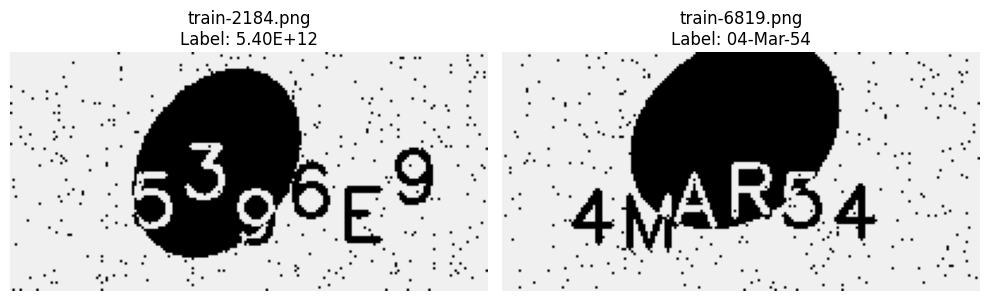

In [ ]:
fig,axes = plt.subplots(1,2,figsize=(10, 3))

for ax, (_, row) in zip(axes,bad_rows.iterrows()):
  img = Image.open(train_dir / row["image"])
  ax.imshow(img)
  ax.set_title(f'{row["image"]}\nLabel: {row["text"]}')
  ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Manual corrections after visual inspection of the two corresponding captcha images
labels.loc[labels["image"] == "train-2184.png", "text"] = "5396E9"
labels.loc[labels["image"] == "train-6819.png", "text"] = "4MAR54"

print("Label length counts after correction:")
print(labels["text"].str.len().value_counts().sort_index())
labels[labels["image"].isin(["train-2184.png","train-6819.png"])]

Label length counts after correction:
text
6    20000
Name: count, dtype: int64


,image,text
2184,train-2184.png,5396E9
6819,train-6819.png,4MAR54


## Image Inspection

In [ ]:
train_images = sorted(os.listdir(train_dir))

for file in train_images[:10]:
  img = Image.open(train_dir/file)
  print(file, img.size, img.mode)

train-0.png (200, 100) RGB
train-1.png (200, 100) RGB
train-10.png (200, 100) RGB
train-100.png (200, 100) RGB
train-1000.png (200, 100) RGB
train-10000.png (200, 100) RGB
train-10001.png (200, 100) RGB
train-10002.png (200, 100) RGB
train-10003.png (200, 100) RGB
train-10004.png (200, 100) RGB


In [ ]:
seed = 42

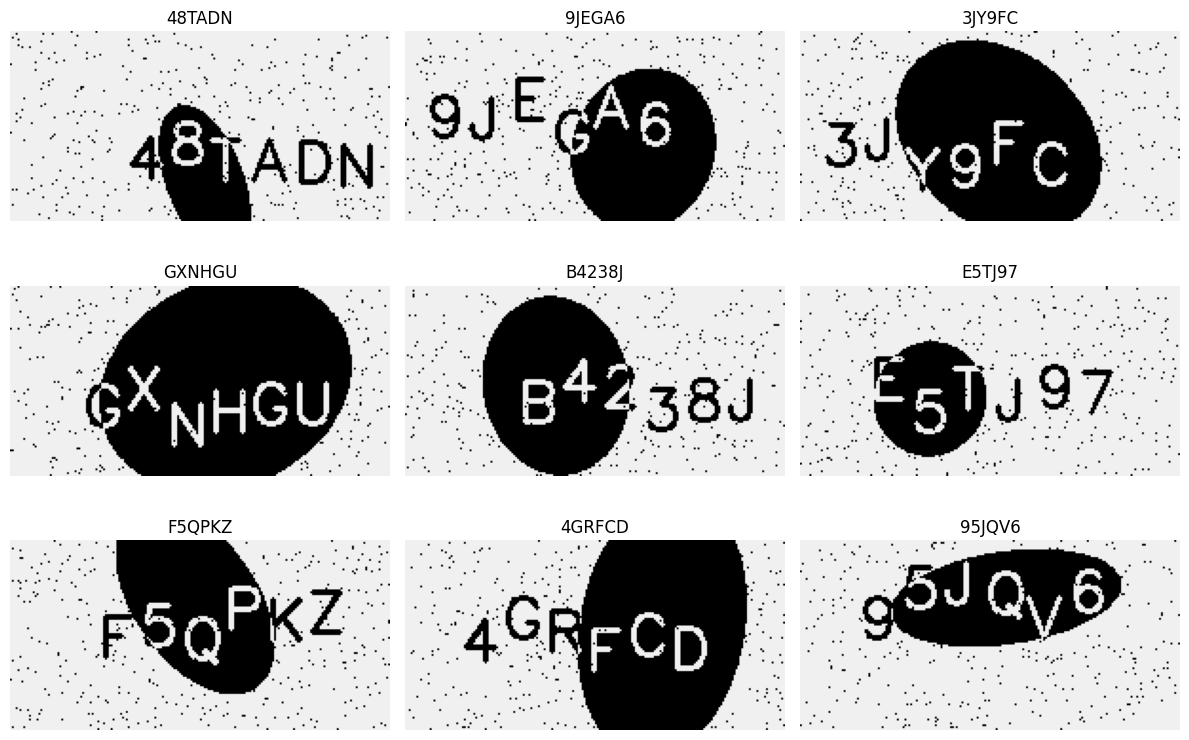

In [ ]:
sample = labels.sample(9, random_state=seed)
plt.figure(figsize=(12,8))

for i, (_, row) in enumerate(sample.iterrows()):
  img = Image.open(train_dir/row["image"])
  plt.subplot(3,3, i + 1)
  plt.imshow(img)
  plt.title(row["text"])
  plt.axis("off")

plt.tight_layout()
plt.show()

## Character Mapping

In [ ]:
all_chars = sorted(set("".join(labels["text"].astype(str))))
num_chars = len(all_chars)

char_to_idx = {ch: i for i,ch in enumerate(all_chars)}
idx_to_char = {i: ch for ch,i in char_to_idx.items()}

print("Number of unique characters:",num_chars)
print("Characters:",all_chars)

Number of unique characters: 31
Characters: ['2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'J', 'K', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


In [ ]:
def encode_text(text):
  return [char_to_idx[ch] for ch in text]

labels["encoded"] = labels["text"].apply(encode_text)
labels.head()

,image,text,encoded
0,train-0.png,BU522X,"[9, 25, 3, 0, 0, 28]"
1,train-1.png,XQ8NE2,"[28, 21, 6, 19, 12, 0]"
2,train-2.png,DTZD3E,"[11, 24, 30, 11, 1, 12]"
3,train-3.png,SM424H,"[23, 18, 2, 0, 2, 15]"
4,train-4.png,6YVTQR,"[4, 29, 26, 24, 21, 22]"


## Train-Validation Split

In [ ]:
train_df, val_df = train_test_split(labels,test_size=0.20,random_state=seed,shuffle=True)

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)

Train shape: (16000, 3)
Validation shape: (4000, 3)


## Data Augmentation and Preprocessing

In [ ]:
train_transform = transforms.Compose([transforms.Grayscale(),transforms.RandomRotation(degrees=5),
                                      transforms.RandomAffine(degrees=0,translate=(0.03, 0.03),scale=(0.95, 1.05)),
                                      transforms.ToTensor(),transforms.Normalize(mean=[0.5], std=[0.5])])

val_transform = transforms.Compose([transforms.Grayscale(),transforms.ToTensor(),transforms.Normalize(mean=[0.5], std=[0.5])])

## Custom OCR Dataset

In [ ]:
class OCRDataset(Dataset):

  def __init__(self, df, image_dir, transform):
    self.df = df.reset_index(drop=True)
    self.image_dir = image_dir
    self.transform = transform

  def __len__(self):
    return len(self.df)

  def __getitem__(self, idx):
    row = self.df.iloc[idx]
    image = Image.open(self.image_dir/row["image"])
    image = self.transform(image)
    label = torch.tensor(row["encoded"],dtype=torch.long)
    return image,label

## Dataset and DataLoader Creation

In [ ]:
g = torch.Generator()
g.manual_seed(seed)

train_dataset = OCRDataset(train_df, train_dir, train_transform)
val_dataset = OCRDataset(val_df, train_dir, val_transform)

train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True,generator=g,num_workers=0,pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset,batch_size=32,shuffle=False,num_workers=0,pin_memory=torch.cuda.is_available())

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

images,labels_batch = next(iter(train_loader))
print("Image batch shape:",images.shape)
print("Label batch shape:",labels_batch.shape)

Train batches: 500
Validation batches: 125
Image batch shape: torch.Size([32, 1, 100, 200])
Label batch shape: torch.Size([32, 6])


## Evaluation Helper Functions

In [ ]:
def decode_predictions(outputs, idx_to_char):
  preds = outputs.argmax(dim=2)
  texts = []
  for row in preds:
    text = "".join(idx_to_char[i.item()] for i in row)
    texts.append(text)
  return texts

In [ ]:
def levenshtein_distance(a, b):
  rows = len(a) + 1
  cols = len(b) + 1
  dp = np.zeros((rows,cols),dtype=int)

  for i in range(rows):
    dp[i][0] = i

  for j in range(cols):
    dp[0][j] = j

  for i in range(1, rows):
    for j in range(1, cols):
      if a[i-1] == b[j-1]:
        cost = 0
      else:
        cost = 1

      dp[i][j] = min(dp[i-1][j]+1, dp[i][j-1]+1, dp[i-1][j-1]+cost)

  return dp[-1][-1]

In [ ]:
def character_error_rate(true_texts, pred_texts):
  total_distance = 0
  total_chars = 0
  for true, pred in zip(true_texts, pred_texts):
    total_distance += levenshtein_distance(true, pred)
    total_chars += len(true)
  return total_distance/total_chars

In [ ]:
def calculate_accuracy(model, data_loader, device):
  model.eval()
  correct_chars = 0
  total_chars = 0
  correct_full = 0
  total_samples = 0

  with torch.no_grad():
    for images, labels_batch in data_loader:
      images = images.to(device)
      labels_batch = labels_batch.to(device)

      outputs = model(images)
      preds = outputs.argmax(dim=2)

      correct_chars += (preds == labels_batch).sum().item()
      total_chars += labels_batch.numel()
      correct_full += (preds == labels_batch).all(dim=1).sum().item()
      total_samples += labels_batch.size(0)

  return correct_chars / total_chars, correct_full / total_samples

In [ ]:
def calculate_cer(model, data_loader, device):
  model.eval()
  all_true = []
  all_pred = []

  with torch.no_grad():
    for images, labels_batch in data_loader:
      images = images.to(device)
      outputs = model(images)
      pred_texts = decode_predictions(outputs, idx_to_char)

      true_texts = []
      for row in labels_batch:
        true_texts.append("".join(idx_to_char[i.item()] for i in row))

      all_true.extend(true_texts)
      all_pred.extend(pred_texts)

  return character_error_rate(all_true, all_pred)

## Training Helper Function

In [ ]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):
  model.train()
  total_loss = 0.0

  for images, labels_batch in train_loader:
    images = images.to(device)
    labels_batch = labels_batch.to(device)
    outputs = model(images)
    loss = 0

    for i in range(6):
      loss += criterion(outputs[:, i, :], labels_batch[:, i])

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    total_loss += loss.item()

  return total_loss / len(train_loader)


In [ ]:
def train_or_load_model(model, model_name, checkpoint_path, train_loader, val_loader, epochs=35, lr=0.001):
  model = model.to(device)
  criterion = nn.CrossEntropyLoss()
  optimizer = optim.Adam(model.parameters(),lr=lr)

  if os.path.exists(checkpoint_path):
    model.load_state_dict(torch.load(checkpoint_path,map_location=device))
    model.to(device)
    val_cer = calculate_cer(model,val_loader,device)
    char_acc,full_acc = calculate_accuracy(model,val_loader,device)
    print(f"Loaded existing {model_name} checkpoint")
    print(f"{model_name} Validation CER: {val_cer:.6f}")
    print(f"{model_name} Char Acc: {char_acc:.4f} | Full Acc: {full_acc:.4f}")
    return model,val_cer

  print(f"No checkpoint found. Training {model_name} from scratch.")
  best_cer = float("inf")
  best_epoch = 0

  for epoch in range(epochs):
    train_loss = train_one_epoch(model,train_loader,criterion,optimizer,device)
    char_acc, full_acc = calculate_accuracy(model,val_loader,device)
    val_cer = calculate_cer(model,val_loader,device)

    print(f"Epoch {epoch + 1}/{epochs} | "
    f"Loss: {train_loss:.4f} | "
    f"Char Acc: {char_acc:.4f} | "
    f"Full Acc: {full_acc:.4f} | "
    f"CER: {val_cer:.6f}")

    if val_cer < best_cer:
      best_cer = val_cer
      best_epoch = epoch + 1
      torch.save(model.state_dict(),checkpoint_path)
      print("Saved best model")

  model.load_state_dict(torch.load(checkpoint_path,map_location=device))
  print(f"Best {model_name} Epoch:",best_epoch)
  print(f"Best {model_name} CER:",best_cer)
  return model,best_cer

# Model Development

The models below are small custom CNN-RNN models. No pretrained weights are used.

## CRNNFixed Architecture

In [ ]:
class CRNNFixed(nn.Module):
  def __init__(self, num_chars):
    super().__init__()

    self.cnn = nn.Sequential(nn.Conv2d(1,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
                             nn.Conv2d(32,64,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
                             nn.Conv2d(64,128,3,padding=1), nn.ReLU(), nn.MaxPool2d((2, 1)),
                             nn.Conv2d(128,256,3,padding=1), nn.ReLU())

    self.pool = nn.AdaptiveAvgPool2d((1, 6))
    self.lstm = nn.LSTM(input_size=256,hidden_size=128,num_layers=2,bidirectional=True,batch_first=True)
    self.fc = nn.Linear(256, num_chars)

  def forward(self, x):
    x = self.cnn(x)
    x = self.pool(x)
    x = x.squeeze(2)
    x = x.permute(0, 2, 1)
    x, _ = self.lstm(x)
    x = self.fc(x)
    return x

## CRNN with Simple Attention Layer

In [ ]:
class AttentionCRNN(nn.Module):
  def __init__(self, num_chars):
    super().__init__()

    self.cnn = nn.Sequential(nn.Conv2d(1,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
                             nn.Conv2d(32,64,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
                             nn.Conv2d(64,128,3,padding=1), nn.ReLU(), nn.MaxPool2d((2, 1)),
                             nn.Conv2d(128,256,3,padding=1), nn.ReLU())

    self.pool = nn.AdaptiveAvgPool2d((1,6))
    self.lstm = nn.LSTM(input_size=256,hidden_size=128,num_layers=2,bidirectional=True,batch_first=True)
    self.attention = nn.Linear(256,1)
    self.fc = nn.Linear(256,num_chars)

  def forward(self, x):
    x = self.cnn(x)
    x = self.pool(x)
    x = x.squeeze(2)
    x = x.permute(0,2,1)
    x, _ = self.lstm(x)
    attn_scores = self.attention(x)
    attn_weights = torch.softmax(attn_scores,dim=1)
    x = x*attn_weights
    x = self.fc(x)
    return x

## GRU CRNN Architecture

In [ ]:
class GRUCRNN(nn.Module):

  def __init__(self, num_chars):
    super().__init__()

    self.cnn = nn.Sequential(nn.Conv2d(1,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
                             nn.Conv2d(32,64,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
                             nn.Conv2d(64,128,3,padding=1), nn.ReLU(), nn.MaxPool2d((2, 1)),
                             nn.Conv2d(128,256,3,padding=1), nn.ReLU())

    self.pool = nn.AdaptiveAvgPool2d((1,6))
    self.gru = nn.GRU(input_size=256,hidden_size=128,num_layers=2,bidirectional=True,batch_first=True)
    self.fc = nn.Linear(256,num_chars)

  def forward(self, x):
    x = self.cnn(x)
    x = self.pool(x)
    x = x.squeeze(2)
    x = x.permute(0,2,1)
    x, _ = self.gru(x)
    x = self.fc(x)
    return x

## Train or Load Individual Models

In [ ]:
EPOCHS = 35

crnn_model = CRNNFixed(num_chars).to(device)
crnn_model, crnn_cer = train_or_load_model(crnn_model,"CRNNFixed","crnn_fixed_best.pth",train_loader,val_loader,epochs=EPOCHS,lr=0.001)

attn_model = AttentionCRNN(num_chars).to(device)
attn_model, attn_cer = train_or_load_model(attn_model,"AttentionCRNN","attention_crnn_best.pth",train_loader,val_loader,epochs=EPOCHS,lr=0.001)

gru_model = GRUCRNN(num_chars).to(device)
gru_model, gru_cer = train_or_load_model(gru_model,"GRUCRNN","gru_crnn_best.pth",train_loader,val_loader,epochs=EPOCHS,lr=0.001)

No checkpoint found. Training CRNNFixed from scratch.
Epoch 1/35 | Loss: 20.6082 | Char Acc: 0.0314 | Full Acc: 0.0000 | CER: 0.968583
Saved best model
Epoch 2/35 | Loss: 19.3288 | Char Acc: 0.1197 | Full Acc: 0.0000 | CER: 0.878417
Saved best model
Epoch 3/35 | Loss: 13.4721 | Char Acc: 0.3243 | Full Acc: 0.0015 | CER: 0.674875
Saved best model
Epoch 4/35 | Loss: 10.2069 | Char Acc: 0.5014 | Full Acc: 0.0158 | CER: 0.497708
Saved best model
Epoch 5/35 | Loss: 7.7140 | Char Acc: 0.6596 | Full Acc: 0.0780 | CER: 0.339875
Saved best model
Epoch 6/35 | Loss: 5.6446 | Char Acc: 0.7697 | Full Acc: 0.2105 | CER: 0.230125
Saved best model
Epoch 7/35 | Loss: 4.0644 | Char Acc: 0.8325 | Full Acc: 0.3340 | CER: 0.167417
Saved best model
Epoch 8/35 | Loss: 3.0469 | Char Acc: 0.8753 | Full Acc: 0.4467 | CER: 0.124667
Saved best model
Epoch 9/35 | Loss: 2.3639 | Char Acc: 0.9093 | Full Acc: 0.5743 | CER: 0.090625
Saved best model
Epoch 10/35 | Loss: 1.8247 | Char Acc: 0.9271 | Full Acc: 0.6515 | CE

## Validation Results of Individual Models

In [ ]:
model_results = pd.DataFrame([{"model": "CRNNFixed", "validation_cer": crnn_cer},{"model": "AttentionCRNN", "validation_cer": attn_cer},{"model": "GRUCRNN", "validation_cer": gru_cer},])
model_results.sort_values("validation_cer")

,model,validation_cer
0,CRNNFixed,0.007000
2,GRUCRNN,0.010667
1,AttentionCRNN,0.016333


## Simple Ensemble Function

In [ ]:
def ensemble_decode(outputs_list, idx_to_char):
  probabilities = [torch.softmax(outputs, dim=2) for outputs in outputs_list]
  avg_probs = sum(probabilities) / len(probabilities)
  preds = avg_probs.argmax(dim=2)

  texts = []
  for row in preds:
    text = "".join(idx_to_char[i.item()] for i in row)
    texts.append(text)

  return texts

## Ensemble Validation CER

In [ ]:
def calculate_ensemble_cer(models, data_loader, device):
  for model in models:
    model.eval()

  all_true = []
  all_pred = []

  with torch.no_grad():
    for images,labels_batch in data_loader:
      images = images.to(device)
      outputs_list = [model(images) for model in models]
      pred_texts = ensemble_decode(outputs_list,idx_to_char)
      true_texts = []

      for row in labels_batch:
        true_texts.append("".join(idx_to_char[i.item()] for i in row))

      all_true.extend(true_texts)
      all_pred.extend(pred_texts)

  return character_error_rate(all_true,all_pred)

ensemble_models = [crnn_model,attn_model,gru_model]
ensemble_cer = calculate_ensemble_cer(ensemble_models,val_loader,device)

print("Final Selected Model: 3-Model Ensemble")
print("Validation CER:", ensemble_cer)

Final Selected Model: 3-Model Ensemble
Validation CER: 0.0016666666666666668


## Test Dataset Preparation

In [ ]:
class TestOCRDataset(Dataset):
  def __init__(self, image_dir, transform):
    self.image_dir = image_dir
    self.image_files = sorted(os.listdir(image_dir))
    self.transform = transform

  def __len__(self):
    return len(self.image_files)

  def __getitem__(self,idx):
    image_name = self.image_files[idx]
    image = Image.open(self.image_dir/image_name)
    image = self.transform(image)
    return image, image_name

test_dataset = TestOCRDataset(test_dir,val_transform)
test_loader = DataLoader(test_dataset,batch_size=32,shuffle=False,num_workers=0,pin_memory=torch.cuda.is_available())

print("Number of test images:",len(test_dataset))

Number of test images: 5000


## Test Dataset Inference

In [ ]:
test_predictions = []

for model in ensemble_models:
  model.eval()

with torch.no_grad():
  for images, image_names in test_loader:
    images = images.to(device)
    outputs_list = [model(images) for model in ensemble_models]
    pred_texts = ensemble_decode(outputs_list,idx_to_char)

    for image_name, pred in zip(image_names, pred_texts):
      test_predictions.append({"image": image_name,"prediction": pred})

submission = pd.DataFrame(test_predictions)
print(submission.shape)
submission.head()

(5000, 2)


,image,prediction
0,test-0.png,QVTQ8A
1,test-1.png,7PSW9D
2,test-10.png,7DUP98
3,test-100.png,75Z4WT
4,test-1000.png,QAKZ7V


## Submission File Generation

In [ ]:
submission_filename = "submission_ChiragKumar_24117040.csv"
submission.to_csv(submission_filename, index=False)

print("Saved:",submission_filename)
print(submission.head())

Saved: submission_ChiragKumar_24117040.csv
           image prediction
0     test-0.png     QVTQ8A
1     test-1.png     7PSW9D
2    test-10.png     7DUP98
3   test-100.png     75Z4WT
4  test-1000.png     QAKZ7V
